In [18]:
import pandas as pd
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor # For regression task
from sklearn.preprocessing import StandardScaler 
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix,classification_report,recall_score
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [19]:
df=pd.read_csv("day.csv")
df


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
726,727,2012-12-27,1,1,12,0,4,1,2,0.254167,0.226642,0.652917,0.350133,247,1867,2114
727,728,2012-12-28,1,1,12,0,5,1,2,0.253333,0.255046,0.590000,0.155471,644,2451,3095
728,729,2012-12-29,1,1,12,0,6,0,2,0.253333,0.242400,0.752917,0.124383,159,1182,1341
729,730,2012-12-30,1,1,12,0,0,0,1,0.255833,0.231700,0.483333,0.350754,364,1432,1796


In [20]:
df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [21]:
df.tail()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
726,727,2012-12-27,1,1,12,0,4,1,2,0.254167,0.226642,0.652917,0.350133,247,1867,2114
727,728,2012-12-28,1,1,12,0,5,1,2,0.253333,0.255046,0.590000,0.155471,644,2451,3095
728,729,2012-12-29,1,1,12,0,6,0,2,0.253333,0.242400,0.752917,0.124383,159,1182,1341
729,730,2012-12-30,1,1,12,0,0,0,1,0.255833,0.231700,0.483333,0.350754,364,1432,1796
730,731,2012-12-31,1,1,12,0,1,1,2,0.215833,0.223487,0.577500,0.154846,439,2290,2729


In [22]:
print("number of rows:", df.shape[0])
print("number of columns:", df.shape[1])

number of rows: 731
number of columns: 16


In [23]:
print(df.describe())

          instant      season          yr        mnth     holiday     weekday  \
count  731.000000  731.000000  731.000000  731.000000  731.000000  731.000000   
mean   366.000000    2.496580    0.500684    6.519836    0.028728    2.997264   
std    211.165812    1.110807    0.500342    3.451913    0.167155    2.004787   
min      1.000000    1.000000    0.000000    1.000000    0.000000    0.000000   
25%    183.500000    2.000000    0.000000    4.000000    0.000000    1.000000   
50%    366.000000    3.000000    1.000000    7.000000    0.000000    3.000000   
75%    548.500000    3.000000    1.000000   10.000000    0.000000    5.000000   
max    731.000000    4.000000    1.000000   12.000000    1.000000    6.000000   

       workingday  weathersit        temp       atemp         hum   windspeed  \
count  731.000000  731.000000  731.000000  731.000000  731.000000  731.000000   
mean     0.683995    1.395349    0.495385    0.474354    0.627894    0.190486   
std      0.465233    0.5448

In [24]:
print(df.describe(include='object'))

            dteday
count          731
unique         731
top     2011-01-01
freq             1


In [25]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB
None


In [26]:
df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [27]:
print("number of duplicate rows:", df.duplicated().sum())

number of duplicate rows: 0


In [28]:
print("season :", sorted(df.season.unique()), "(expected 1-4)")
print("weathersit :", sorted(df.weathersit.unique()), "(expected 1-4)")
print("holiday :", sorted(df.holiday.unique()), "(expected 0-1)")
print("workingday :", sorted(df.workingday.unique()), "(expected 0-1)")

season : [np.int64(1), np.int64(2), np.int64(3), np.int64(4)] (expected 1-4)
weathersit : [np.int64(1), np.int64(2), np.int64(3)] (expected 1-4)
holiday : [np.int64(0), np.int64(1)] (expected 0-1)
workingday : [np.int64(0), np.int64(1)] (expected 0-1)


In [29]:
mismatch= (df["casual"] + df["registered"]!= df["cnt"]).sum
print("\n rows where cnt != casual + registered:", mismatch)


 rows where cnt != casual + registered: <bound method Series.sum of 0      False
1      False
2      False
3      False
4      False
       ...  
726    False
727    False
728    False
729    False
730    False
Length: 731, dtype: bool>


In [30]:
numeric_cols = ["temp","atemp","hum","windspeed","casual","registered","cnt"]


for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outlier_count = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    print(f"{col}: {outlier_count} outliers")

temp: 0 outliers
atemp: 0 outliers
hum: 2 outliers
windspeed: 13 outliers
casual: 44 outliers
registered: 0 outliers
cnt: 0 outliers


In [31]:
df[df['hum'] < 0.05][['dteday', 'hum', 'weathersit']]

,dteday,hum,weathersit
68,2011-03-10,0.0,3


In [32]:
median_hum = df['hum'].median()
df.loc[df['hum'] < 0.05, 'hum'] = median_hum

print("Fixed! New min humidity value:", df['hum'].min())

Fixed! New min humidity value: 0.187917


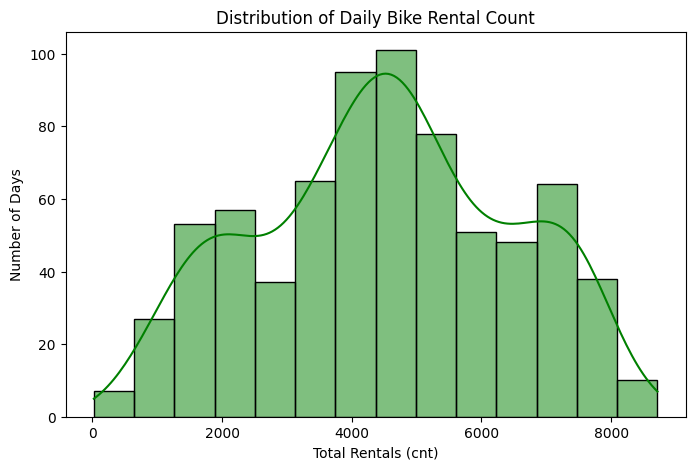

In [33]:
plt.figure(figsize=(8,5))
sns.histplot(df['cnt'], kde = True , color='green')
plt.title('Distribution of Daily Bike Rental Count')
plt.xlabel('Total Rentals (cnt)')
plt.ylabel('Number of Days')
plt.show()

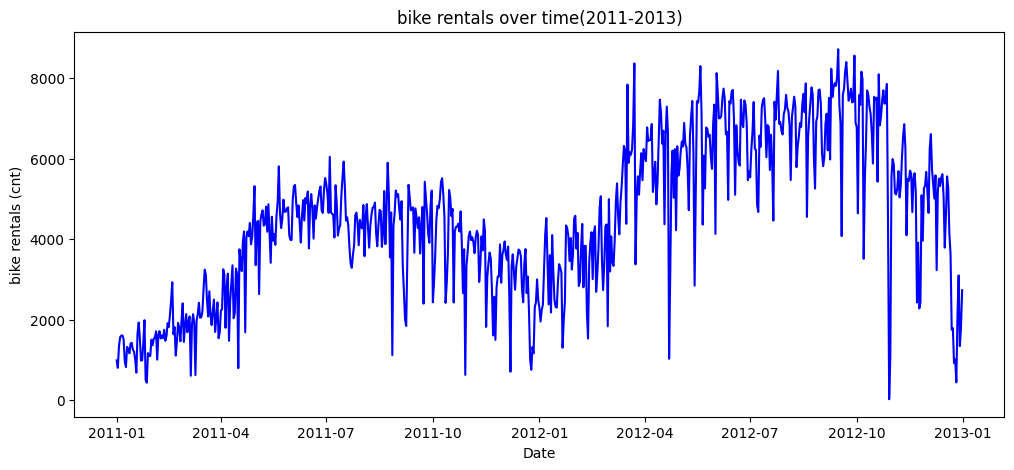

In [34]:
df['dteday'] = pd.to_datetime(df['dteday'])

plt.figure(figsize = (12,5))
plt.plot(df['dteday'], df['cnt'], color='blue')
plt.title('bike rentals over time(2011-2013)')
plt.xlabel('Date')
plt.ylabel('bike rentals (cnt)')
plt.show()

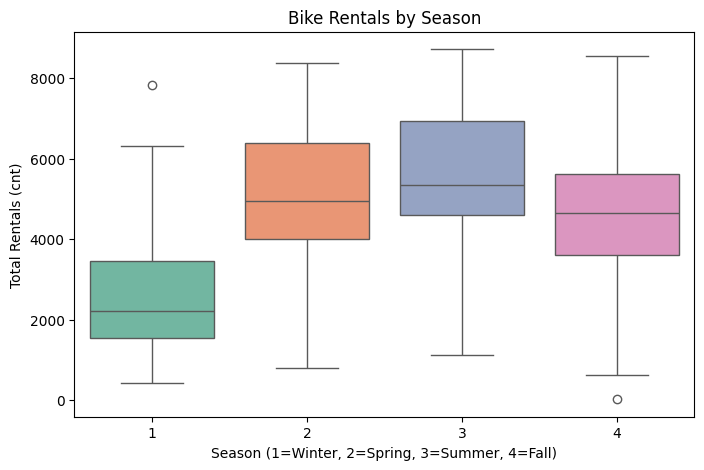

In [35]:
plt.figure(figsize=(8,5))
sns.boxplot(x='season', y='cnt', data=df, palette='Set2')
plt.title('Bike Rentals by Season')
plt.xlabel('Season (1=Winter, 2=Spring, 3=Summer, 4=Fall)')
plt.ylabel('Total Rentals (cnt)')
plt.show()

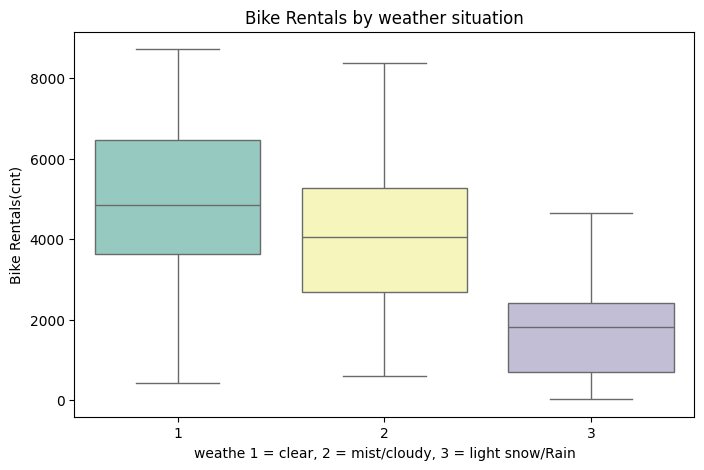

In [36]:
plt.figure(figsize=(8,5))
sns.boxplot(x = 'weathersit', y = 'cnt', data = df, palette = 'Set3')
plt.title('Bike Rentals by weather situation')
plt.xlabel('weathe 1 = clear, 2 = mist/cloudy, 3 = light snow/Rain')
plt.ylabel('Bike Rentals(cnt)')
plt.show()

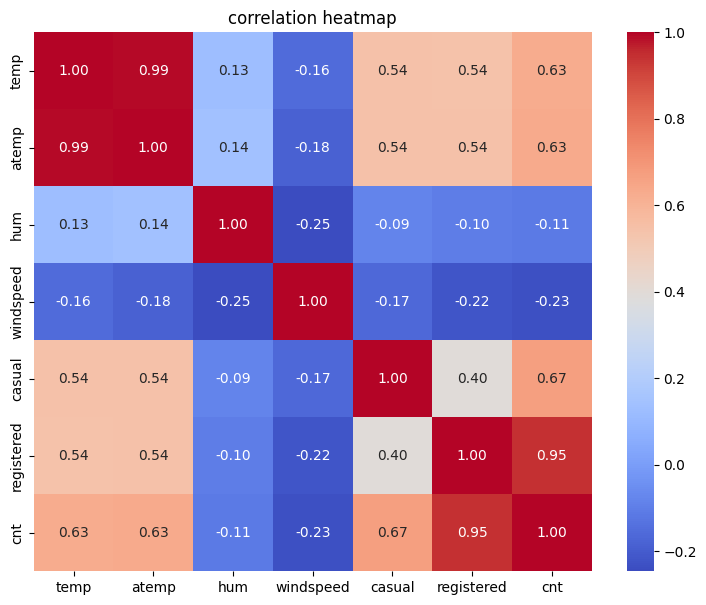

In [37]:
plt.figure(figsize=(9,7))
numeric_cols= ['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot = True, fmt = '.2f', cmap = 'coolwarm')
plt.title('correlation heatmap')
plt.show()

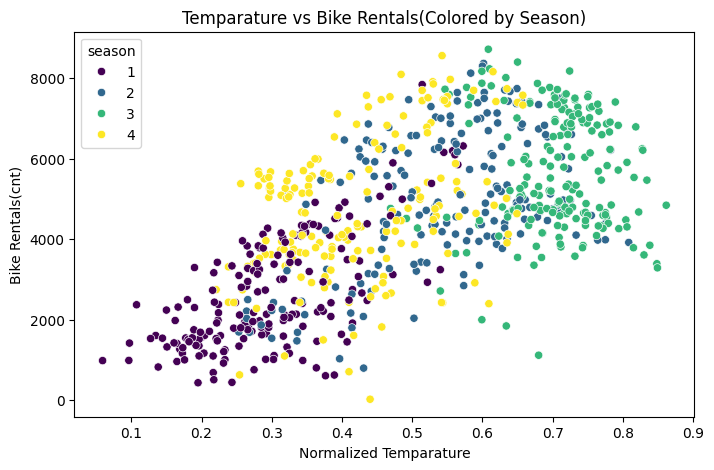

In [38]:
plt.figure(figsize = (8,5))
sns.scatterplot(x = 'temp', y = 'cnt', data = df, hue = 'season', palette = 'viridis')
plt.title('Temparature vs Bike Rentals(Colored by Season)')
plt.xlabel('Normalized Temparature')
plt.ylabel('Bike Rentals(cnt)')
plt.show()

In [39]:
print("correlation between temp and atemp:",df['temp'].corr(df['atemp']))

correlation between temp and atemp: 0.991701553229463


In [40]:
model_df = df.copy()


In [41]:
model_df = df.drop(columns=['instant', 'dteday', 'casual', 'registered', 'atemp'])
print('Remaining columns:', list (model_df.columns))

Remaining columns: ['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'hum', 'windspeed', 'cnt']


In [43]:
print(model_df.columns)

Index(['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday',
       'weathersit', 'temp', 'hum', 'windspeed', 'cnt'],
      dtype='object')


In [44]:
categorical_cols = ['season', 'weathersit', 'mnth', 'weekday']
model_df = pd.get_dummies(model_df, columns=categorical_cols, drop_first=True)

print("Shape after encoding:", model_df.shape)
model_df.head()

Shape after encoding: (731, 29)


,yr,holiday,workingday,temp,hum,windspeed,cnt,season_2,season_3,season_4,...,mnth_9,mnth_10,mnth_11,mnth_12,weekday_1,weekday_2,weekday_3,weekday_4,weekday_5,weekday_6
0,0,0,0,0.344167,0.805833,0.160446,985,False,False,False,...,False,False,False,False,False,False,False,False,False,True
1,0,0,0,0.363478,0.696087,0.248539,801,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,0,0,1,0.196364,0.437273,0.248309,1349,False,False,False,...,False,False,False,False,True,False,False,False,False,False
3,0,0,1,0.200000,0.590435,0.160296,1562,False,False,False,...,False,False,False,False,False,True,False,False,False,False
4,0,0,1,0.226957,0.436957,0.186900,1600,False,False,False,...,False,False,False,False,False,False,True,False,False,False


In [45]:
X = model_df.drop(columns=['cnt'])
y = model_df['cnt']

print("X shape (features):", X.shape)
print("y shape (target):", y.shape)

X shape (features): (731, 28)
y shape (target): (731,)


In [46]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)

Training set size: (584, 28)
Testing set size: (147, 28)


In [47]:
num_cols = ['temp', 'hum', 'windspeed']

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

print("Scaling done!")
X_train_scaled[num_cols].describe()

Scaling done!


,temp,hum,windspeed
count,5.840000e+02,5.840000e+02,5.840000e+02
mean,-2.372531e-16,-6.691755e-17,2.250863e-16
std,1.000857e+00,1.000857e+00,1.000857e+00
min,-2.431352e+00,-2.707965e+00,-2.175877e+00
25%,-8.646102e-01,-7.823584e-01,-7.285233e-01
50%,7.256226e-02,1.519463e-02,-1.416860e-01
75%,8.592777e-01,7.284386e-01,5.600706e-01
max,1.992842e+00,2.365320e+00,3.243735e+00


In [51]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

In [52]:
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42, n_estimators=100),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42)
}

print("Models ready:", list(models.keys()))

Models ready: ['Linear Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting']


In [53]:
trained_models = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model
    print(f"{name} training done!")

Linear Regression training done!
Decision Tree training done!
Random Forest training done!
Gradient Boosting training done!


In [55]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [56]:
results = []

for name, model in trained_models.items():
    preds = model.predict(X_test_scaled)
    r2 = r2_score(y_test, preds)
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    results.append([name, r2, mae, rmse])

results_df = pd.DataFrame(results, columns=['Model', 'R2 Score', 'MAE', 'RMSE'])
results_df = results_df.sort_values('R2 Score', ascending=False).reset_index(drop=True)
results_df

,Model,R2 Score,MAE,RMSE
0,Gradient Boosting,0.892886,473.775973,655.373217
1,Random Forest,0.872692,466.802109,714.486200
2,Linear Regression,0.840118,586.436682,800.692542
3,Decision Tree,0.746422,643.523810,1008.374708


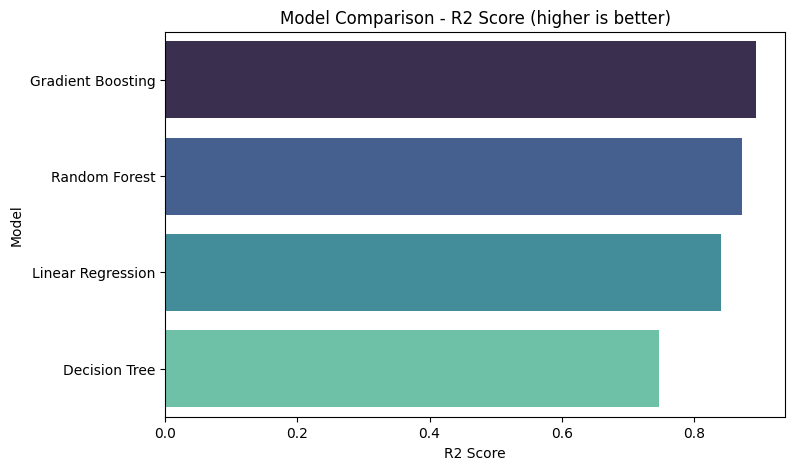

In [58]:
plt.figure(figsize=(8,5))
sns.barplot(x='R2 Score', y='Model', data=results_df, palette='mako')
plt.title('Model Comparison - R2 Score (higher is better)')
plt.xlabel('R2 Score')
plt.show()

In [59]:
best_model_name = results_df.iloc[0]['Model']
best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)
print("R2 Score:", results_df.iloc[0]['R2 Score'])

Best Model: Gradient Boosting
R2 Score: 0.8928861190722389


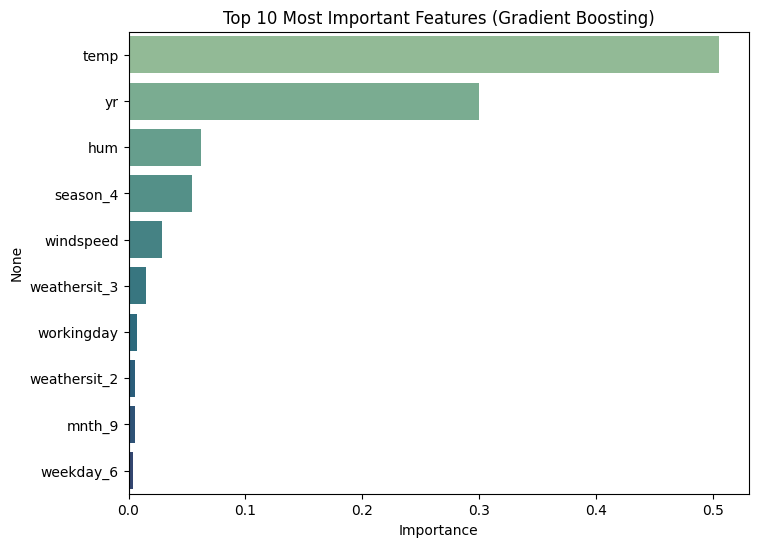

In [61]:
importance = pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8,6))
sns.barplot(x=importance.head(10).values, y=importance.head(10).index, palette='crest')
plt.title('Top 10 Most Important Features (Gradient Boosting)')
plt.xlabel('Importance')
plt.show()

In [62]:
sample_day = X_test.iloc[[0]].copy()  
print("Sample input (before scaling):")
sample_day

Sample input (before scaling):


,yr,holiday,workingday,temp,hum,windspeed,season_2,season_3,season_4,weathersit_2,...,mnth_9,mnth_10,mnth_11,mnth_12,weekday_1,weekday_2,weekday_3,weekday_4,weekday_5,weekday_6
703,1,0,1,0.475833,0.73375,0.174129,False,False,True,False,...,False,False,False,True,False,True,False,False,False,False


In [63]:
sample_scaled = sample_day.copy()
sample_scaled[num_cols] = scaler.transform(sample_day[num_cols])

predicted_cnt = best_model.predict(sample_scaled)[0]
actual_cnt = y_test.iloc[0]

print(f"Predicted bike rentals: {predicted_cnt:.0f}")
print(f"Actual bike rentals:    {actual_cnt}")
print(f"Difference:             {abs(predicted_cnt - actual_cnt):.0f} bikes")

Predicted bike rentals: 6508
Actual bike rentals:    6606
Difference:             98 bikes


# Model Comparison Report

In [ ]:
Model	            R² Score	MAE	    RMSE	Verdict
Gradient Boosting	0.893	    473.8	655.4	Best — Recommended for production
Random Forest	    0.873	    466.8	714.5	Good, close second, more interpretable (feature importance)
Linear Regression	0.840	    586.4	800.7	Decent baseline, but assumes straight-line relationships
Decision Tree	    0.746	    643.5	1008.4	Weakest — overfits, single-tree instabilit

# Report on Challenges Faced

In [ ]:
              Challenge                              Technique Used	                       Reasoning
1.Incorrect data: Humidity reading of                Replace with median             The median provides a realistic and robust 
0.0 on a day—which is physically impossible                                           replacement, unaffected by outliers.
—especially on a day when it was raining.

2.Multicollinearity: 'temp' and 'atemp' have        We removed 'atemp'.              Since both provide essentially the same information,
     a correlation of 0.99.                                                           keeping just one is sufficient; this keeps the model simple.

3.Data Leakage Risk: casual + register              We removed these two columns     Since the 'casual' or 'registered' status is not known 
            = cnt (target)                                from the features.          before the start of a new day, using these variables 
                                                                                      makes the model unsuitable for production.

4.Categorical columns (encoded as numbers),          Let's use One-Hot Encoding       Even though they appear as numbers, these are merely
         e.g., season (1-4)                                                            categories—to prevent the model from inferring an 
                                                                                        incorrect "order" among them.

5.Natural Outliers (in windspeed, casual)           We didn't remove it; we kept        These are not errors—they represent actual instances
                                                            it as it is.                 of extreme weather or holidays; excluding them would       
                                                                                         leave the real-world variation model unaware of these factors.

6.Natural Outliers (in windspeed, casual)           We didn't remove it; we kept it    These are not errors—they represent actual instances of
                                                         as it is.                       extreme weather or holidays; excluding them would leave
                                                                                        the real-world variation model unaware of these factors.

7.Small dataset (731 rows)                       Let's use rain-Test split (80-20) +     Ensemble methods (Random Forest, Gradient Boosting) 
                                                       Ensemble models                    generalize well even on small datasets and reduce 
                                                                                          overfitting.
                                                     
                                                       
                                                                                        
    
       
    


# Final Conclusion

In [ ]:
Temperature has the greatest impact on bike rentals—rentals are higher on warm days.
The year 2012 saw 64% higher average rentals compared to 2011, indicating significant business growth.
Rentals peak during the summer season and are at their lowest in winter.
Rentals are high during clear weather but drop drastically during rain or snow.
The impact of working days versus holidays is minimal.